# 03 - Tổng hợp: drift, ngưỡng cảnh báo, người xác minh, vòng đời
Đọc kết quả đã sinh bởi `experiments/` (chạy `python experiments/run_all.py` trước).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # de import duoc package `src`
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import load_config
from src.preprocessing.data_loader import load_raw, load_splits, to_xy
cfg = load_config()
import json
from src.config import path_of
T = lambda n: json.load(open(path_of(cfg, "metrics_dir", n), encoding="utf-8"))
drift, pol, rt = T("drift_monitoring.json"), T("alert_policy_hitl.json"), T("retrain_comparison.json")

## 1. Hiệu năng khi dữ liệu drift (ngưỡng đóng băng)

In [2]:
rows = []
for sc, r in drift.items():
    for n, m in r["models"].items():
        p = m["performance_at_frozen_threshold"]
        rows.append({"kịch bản": sc, "mô hình": n, "feature PSI≥ngưỡng": m["n_feature_alert"], "tỉ lệ dự đoán TC": round(m["alert_rate_ratio"], 2),
                     "giám sát không nhãn": m["label_free_status"], "precision": p["precision"], "recall": p["recall"], "f1": p["f1"], "hiệu năng": m["perf_status"]})
pd.DataFrame(rows).round(3)

,kịch bản,mô hình,feature PSI≥ngưỡng,tỉ lệ dự đoán TC,giám sát không nhãn,precision,recall,f1,hiệu năng
0,control (khong drift),random_forest,0,1.00,STABLE,0.999,0.997,0.998,OK
1,control (khong drift),logreg,0,0.99,STABLE,0.967,0.949,0.958,OK
2,covariate_network,random_forest,17,0.47,DRIFT,0.995,0.466,0.635,DEGRADED
3,covariate_network,logreg,17,0.99,DRIFT,0.966,0.951,0.959,OK
4,prevalence_low,random_forest,0,0.21,DRIFT,0.995,1.000,0.997,OK
5,prevalence_low,logreg,0,0.24,DRIFT,0.861,0.949,0.903,DEGRADED
6,evasion_low_slow,random_forest,0,0.24,DRIFT,0.996,0.237,0.383,DEGRADED
7,evasion_low_slow,logreg,0,0.99,STABLE,0.967,0.951,0.959,OK
8,combined,random_forest,17,0.04,DRIFT,0.917,0.168,0.284,DEGRADED
9,combined,logreg,17,0.24,DRIFT,0.854,0.954,0.901,DEGRADED


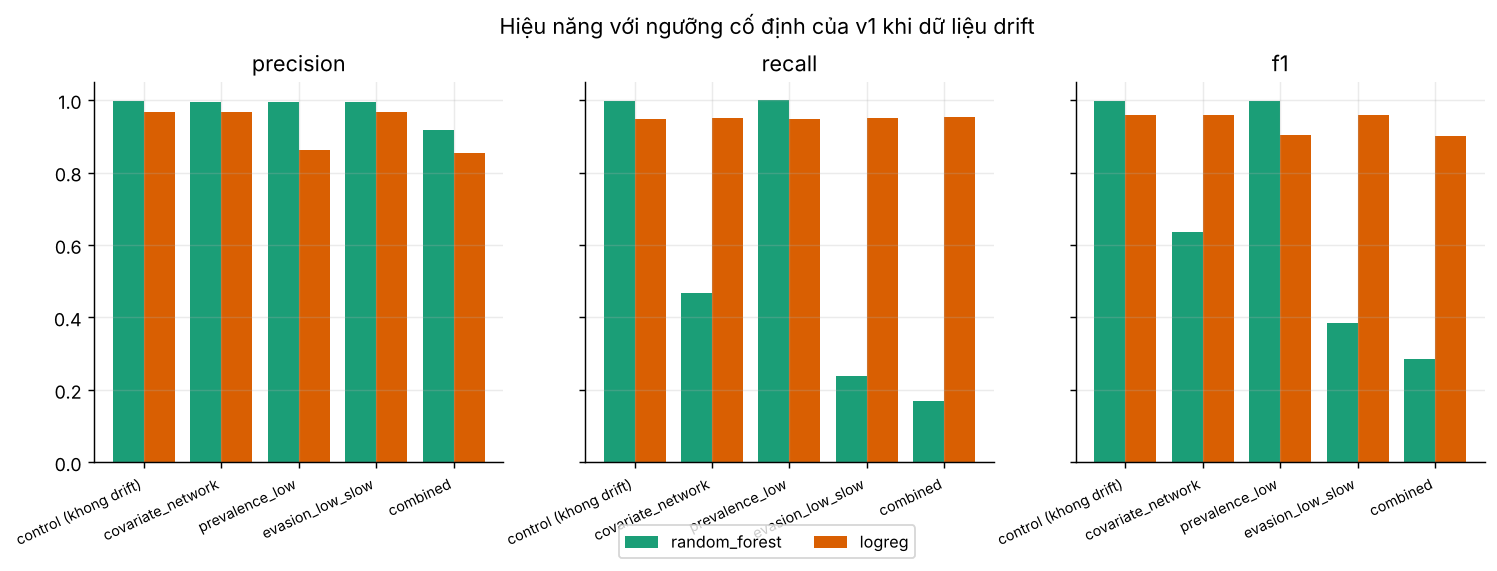

In [3]:
from IPython.display import Image
Image(filename=str(path_of(cfg, "figures_dir", "05_performance_under_drift.png")))

## 2. Hàng đợi người xác minh: recall chỉ-máy so với máy+người

In [4]:
pd.DataFrame(pol["triage_by_scenario"]).T[["recall_auto_only", "recall_with_human", "recall_with_human_if_analyst_perfect", "human_queue_share", "missed_in_ignore"]].round(4)

,recall_auto_only,recall_with_human,recall_with_human_if_analyst_perfect,human_queue_share,missed_in_ignore
control,0.996805,0.971246,0.998935,0.02515,1
covariate_network,0.466454,0.968051,0.99574,0.025025,4
prevalence_low,1.0,0.984694,1.0,0.006725,0
evasion_low_slow,0.237487,0.952077,0.978701,0.024675,20
combined,0.168367,0.933673,0.964286,0.006394,7


## 3. Khối lượng analyst theo tỷ lệ tấn công thực tế (giả định trong config)

In [5]:
pd.DataFrame(pol["workload_projection"])[["prevalence", "tp_alerts_per_day", "fp_alerts_per_day", "analyst_shifts_per_day", "queue_precision"]].round(3)

,prevalence,tp_alerts_per_day,fp_alerts_per_day,analyst_shifts_per_day,queue_precision
0,0.000,0.500,630.578,4.508,0.001
1,0.001,4.997,630.011,4.536,0.008
2,0.005,24.986,627.488,4.661,0.038
3,0.010,49.973,624.335,4.816,0.074
4,0.023,117.329,615.835,5.237,0.160


## 4. Retrain và versioning

In [6]:
for name, r in rt["models"].items():
    print(name, "→", r["decision"], f"(ΔF1 drift = {r['f1_gain_on_drift']:+.3f})")
    display(pd.DataFrame({k: v["drift_eval"] for k, v in r["table"].items()}).T[["precision", "recall", "f1", "fp"]].round(3))

random_forest → PROMOTE (ΔF1 drift = +0.619)


,precision,recall,f1,fp
v1 (khong doi),1.000,0.231,0.375,0.0
v1 + chinh lai nguong,0.973,0.973,0.973,14.0
v2 retrain,1.000,0.988,0.994,0.0


logreg → PROMOTE (ΔF1 drift = +0.009)


,precision,recall,f1,fp
v1 (khong doi),0.968,0.94,0.954,16.0
v1 + chinh lai nguong,0.968,0.94,0.954,16.0
v2 retrain,0.986,0.94,0.962,7.0


In [9]:
from src.models.model_loader import get_registry

reg = get_registry(cfg)
for name, versions in reg._read()["models"].items():
    for e in versions:
        m = e["metrics"]
        print(f"{name:14s} {e['version']:3s} {e['stage']:10s} F1={m.get('f1', float('nan')):.4f}  parent={e['parent_version']}")

random_forest  v1  archived   F1=0.9973  parent=None
random_forest  v2  production F1=0.9970  parent=v1
logreg         v1  archived   F1=0.9600  parent=None
logreg         v2  production F1=0.9708  parent=v1
